# Clustering Methods Exercises

![Clustering.png](Assets/Clustering.png)

# Цели обучения

- Обсудить алгоритмы обучения без учителя и способы их применения
- Применять кластеризацию
- Применять снижение размерности

## Введение

Для этих упражнений мы будем использовать набор данных о качестве вина. Этот набор данных содержит различные химические характеристики вина, такие как кислотность, содержание сахара, pH и содержание алкоголя. Он также содержит показатель качества (от 3 до 9, где более высокое значение означает лучшее качество) и цвет (красное или белое). Имя файла — `Wine_Quality_Data`.

Мы будем использовать химические свойства (то есть все, кроме показателя качества и цвета) для кластеризации вин. Хотя это обучение без учителя, может быть интересно посмотреть, как результаты нашей кластеризации соотносятся с цветом и качеством.

> **Пояснение**
> - До сих пор у нас всегда был «правильный ответ» (отток клиента, вид активности). Здесь ответа **нет**: мы просим алгоритм самого разбить вина на группы (**кластеры**) по их химическим свойствам.
> - **K-средних (K-Means)** — задаём число кластеров `k`, алгоритм находит `k` «центров», и каждое вино относит к ближайшему центру.
> - **Агломеративная кластеризация** — начинает с того, что каждое вино — отдельный кластер, и шаг за шагом объединяет самые похожие кластеры. Результат можно нарисовать в виде дерева — **дендрограммы**.
> - Так как алгоритмы считают расстояния между объектами, признаки должны быть в **одном масштабе** и без сильных «перекосов» — поэтому в вопросе 2 мы преобразуем и масштабируем данные.
> - Цвет и качество вина мы алгоритму **не показываем**, а потом смотрим, совпали ли найденные кластеры с цветом.

In [2]:
from __future__ import print_function
import os
data_path = [  'data']

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.cluster import KMeans
from sklearn.cluster import DBSCAN
from sklearn.cluster import AgglomerativeClustering
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score
from sklearn.model_selection import StratifiedShuffleSplit

# Библиотеки для работы с таблицами и графиками
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

# Функции SciPy для дендрограммы (понадобятся в вопросе 5)
from scipy.cluster.hierarchy import linkage, dendrogram

## Вопрос 1

* Импортируйте данные и проанализируйте характеристики.
* Определите, какие из них являются непрерывными, категориальными и булевыми.
* Сколько записей имеется для двух цветов вина и диапазона показателей качества?
* Постройте гистограмму показателя качества для каждого из цветов вина.

> **Пояснение**
> - Читаем CSV в таблицу `data`, смотрим размер и первые строки.
> - `dtypes` показывает тип каждого столбца: `float64` — дробные числа (непрерывные признаки), `int64` — целые, `object` — текст (категории).
> - `value_counts()` считает, сколько записей каждого цвета; `pd.crosstab` строит таблицу «качество × цвет».
> - Гистограммы рисуем отдельно для красных и белых вин, чтобы сравнить, как распределено качество. Красных вин заметно меньше, поэтому на графиках показываем **доли**, а не количество (`density=True`).

In [3]:
filepath = os.sep.join(data_path + ['Wine_Quality_Data.csv'])
data = pd.read_csv(filepath, sep=',')

# Размер таблицы и первые строки
print(data.shape)
data.head()

(6497, 13)


,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,quality,color
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,red
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,red
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,red
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red


In [4]:
# Типы данных каждого столбца
print(data.dtypes)
print()

# Количество столбцов каждого типа
data.dtypes.value_counts()

fixed_acidity           float64
volatile_acidity        float64
citric_acid             float64
residual_sugar          float64
chlorides               float64
free_sulfur_dioxide     float64
total_sulfur_dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                 float64
quality                   int64
color                       str
dtype: object



float64    11
int64       1
str         1
Name: count, dtype: int64

In [5]:
float_columns = [c for c in data.columns if c not in ['quality', 'color']]
data[float_columns] = data[float_columns].astype(float)

categorical_columns = ['color']   # категориальный признак (текст: red / white)
ordinal_columns = ['quality']     # целое число, порядковый признак (оценка от 3 до 9)

print('Непрерывные (float):', float_columns)
print()
print('Категориальные:', categorical_columns)
print()
print('Порядковые (целые числа):', ordinal_columns)

Непрерывные (float): ['fixed_acidity', 'volatile_acidity', 'citric_acid', 'residual_sugar', 'chlorides', 'free_sulfur_dioxide', 'total_sulfur_dioxide', 'density', 'pH', 'sulphates', 'alcohol']

Категориальные: ['color']

Порядковые (целые числа): ['quality']


In [6]:
# Сколько записей каждого цвета
print(data['color'].value_counts())
print()

# Сколько записей для каждого значения качества, отдельно по цветам
pd.crosstab(data['quality'], data['color'])

color
white    4898
red      1599
Name: count, dtype: int64



color,red,white
quality,,
3,10,20
4,53,163
5,681,1457
6,638,2198
7,199,880
8,18,175
9,0,5


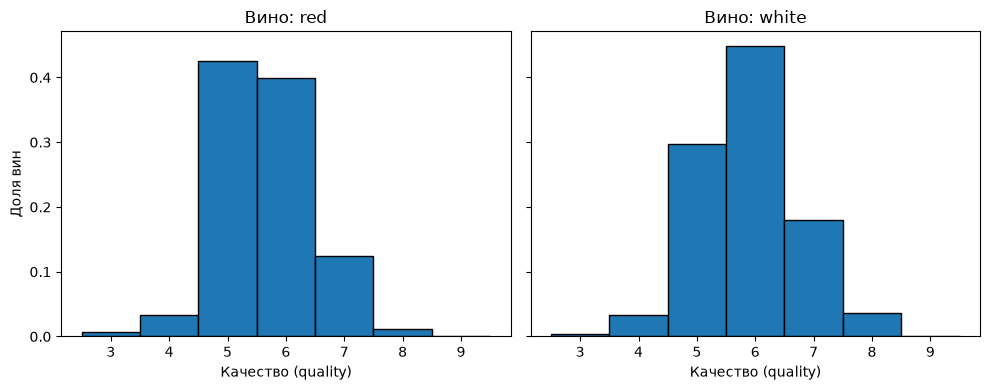

In [7]:
# Гистограммы качества для каждого цвета (рядом, с одинаковой осью Y)
colors = data['color'].unique()
bins = np.arange(data['quality'].min() - 0.5, data['quality'].max() + 1.5, 1)

fig, axList = plt.subplots(ncols=len(colors), figsize=(5 * len(colors), 4), sharey=True)

for ax, color in zip(axList, colors):
    ax.hist(data.loc[data['color'] == color, 'quality'], bins=bins, density=True, edgecolor='black')
    ax.set(title='Вино: ' + str(color), xlabel='Качество (quality)')
axList[0].set_ylabel('Доля вин')

plt.tight_layout()
plt.show()

Типы данных для каждой записи. Реализация алгоритма K-means в библиотеке Scikit-learn рассчитана исключительно на работу с непрерывными данными (хотя иногда её применяют и для категориальных или булевых типов). К счастью, все столбцы, которые мы будем использовать (все, кроме «quality» и «color»), являются непрерывными.

## Вопрос 2

* Оцените корреляцию и асимметрию соответствующих переменных — всех, кроме цвета и качества.
* Проведите необходимые преобразования признаков и/или масштабирование.
* Проанализируйте парное распределение переменных с помощью парных графиков, чтобы проверить правильность масштабирования и нормализации.

> **Пояснение**
> - **Корреляция** показывает, насколько два признака «ходят вместе» (от -1 до 1). Сильно связанные признаки несут похожую информацию.
> - **Асимметрия (skew)** показывает, «перекошено» ли распределение. Если skew заметно больше 0 — у распределения длинный «хвост» вправо (много маленьких значений и несколько очень больших). Такой хвост сильно влияет на расстояния между объектами.
> - Чтобы убрать правый хвост, применяем **логарифм** (`np.log1p`) к сильно асимметричным признакам (skew > 0,75).
> - Затем **масштабируем** все признаки (`StandardScaler`: вычитаем среднее и делим на стандартное отклонение), чтобы у каждого признака среднее было 0, а разброс 1. Иначе признаки с большими числами (например, диоксид серы) «задавят» остальные при подсчёте расстояний.
> - **Парные графики (pairplot)** — сетка из диаграмм рассеяния для каждой пары признаков и гистограмм на диагонали. Смотрим, что распределения стали более симметричными и в одном масштабе.

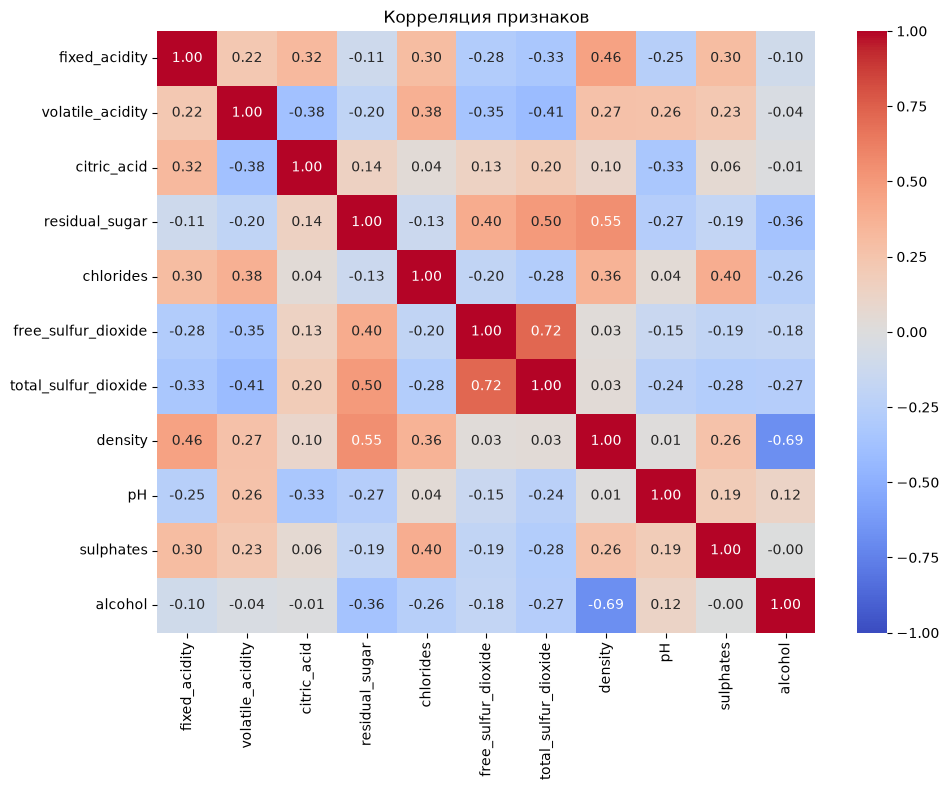

In [8]:
# Корреляционная матрица признаков (без цвета и качества) в виде тепловой карты
correlation_matrix = data[float_columns].corr()

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, ax=ax)
ax.set_title('Корреляция признаков')
plt.tight_layout()
plt.show()

А также анализ значений асимметрии в преддверии преобразований.

In [9]:
# Асимметрия каждого признака, от самой большой к самой маленькой
skew_before = data[float_columns].skew().sort_values(ascending=False)
skew_before

chlorides               5.399828
sulphates               1.797270
fixed_acidity           1.723290
volatile_acidity        1.495097
residual_sugar          1.435404
free_sulfur_dioxide     1.220066
alcohol                 0.565718
density                 0.503602
citric_acid             0.471731
pH                      0.386839
total_sulfur_dioxide   -0.001177
dtype: float64

In [10]:
# Выбираем признаки с сильной правосторонней асимметрией (skew > 0.75)
skew_limit = 0.75
skewed_columns = skew_before[skew_before > skew_limit].index.tolist()
print('Применяем логарифм к:', skewed_columns)

# log1p = log(1 + x): безопасный логарифм, работает и для значений, равных 0
for col in skewed_columns:
    data[col] = np.log1p(data[col])

# Масштабируем ВСЕ непрерывные признаки: среднее 0, стандартное отклонение 1
scaler = StandardScaler()
data[float_columns] = scaler.fit_transform(data[float_columns])

# Проверка: асимметрия после преобразований и среднее/разброс после масштабирования
pd.DataFrame({
    'skew до': skew_before,
    'skew после': data[float_columns].skew(),
    'среднее': data[float_columns].mean().round(3),
    'std': data[float_columns].std().round(3)
})

Применяем логарифм к: ['chlorides', 'sulphates', 'fixed_acidity', 'volatile_acidity', 'residual_sugar', 'free_sulfur_dioxide']


,skew до,skew после,среднее,std
alcohol,0.565718,0.565718,0.0,1.0
chlorides,5.399828,4.484421,0.0,1.0
citric_acid,0.471731,0.471731,0.0,1.0
density,0.503602,0.503602,-0.0,1.0
fixed_acidity,1.723290,0.976702,-0.0,1.0
free_sulfur_dioxide,1.220066,-0.721434,-0.0,1.0
pH,0.386839,0.386839,0.0,1.0
residual_sugar,1.435404,0.414917,0.0,1.0
sulphates,1.797270,1.098588,-0.0,1.0
total_sulfur_dioxide,-0.001177,-0.001177,-0.0,1.0


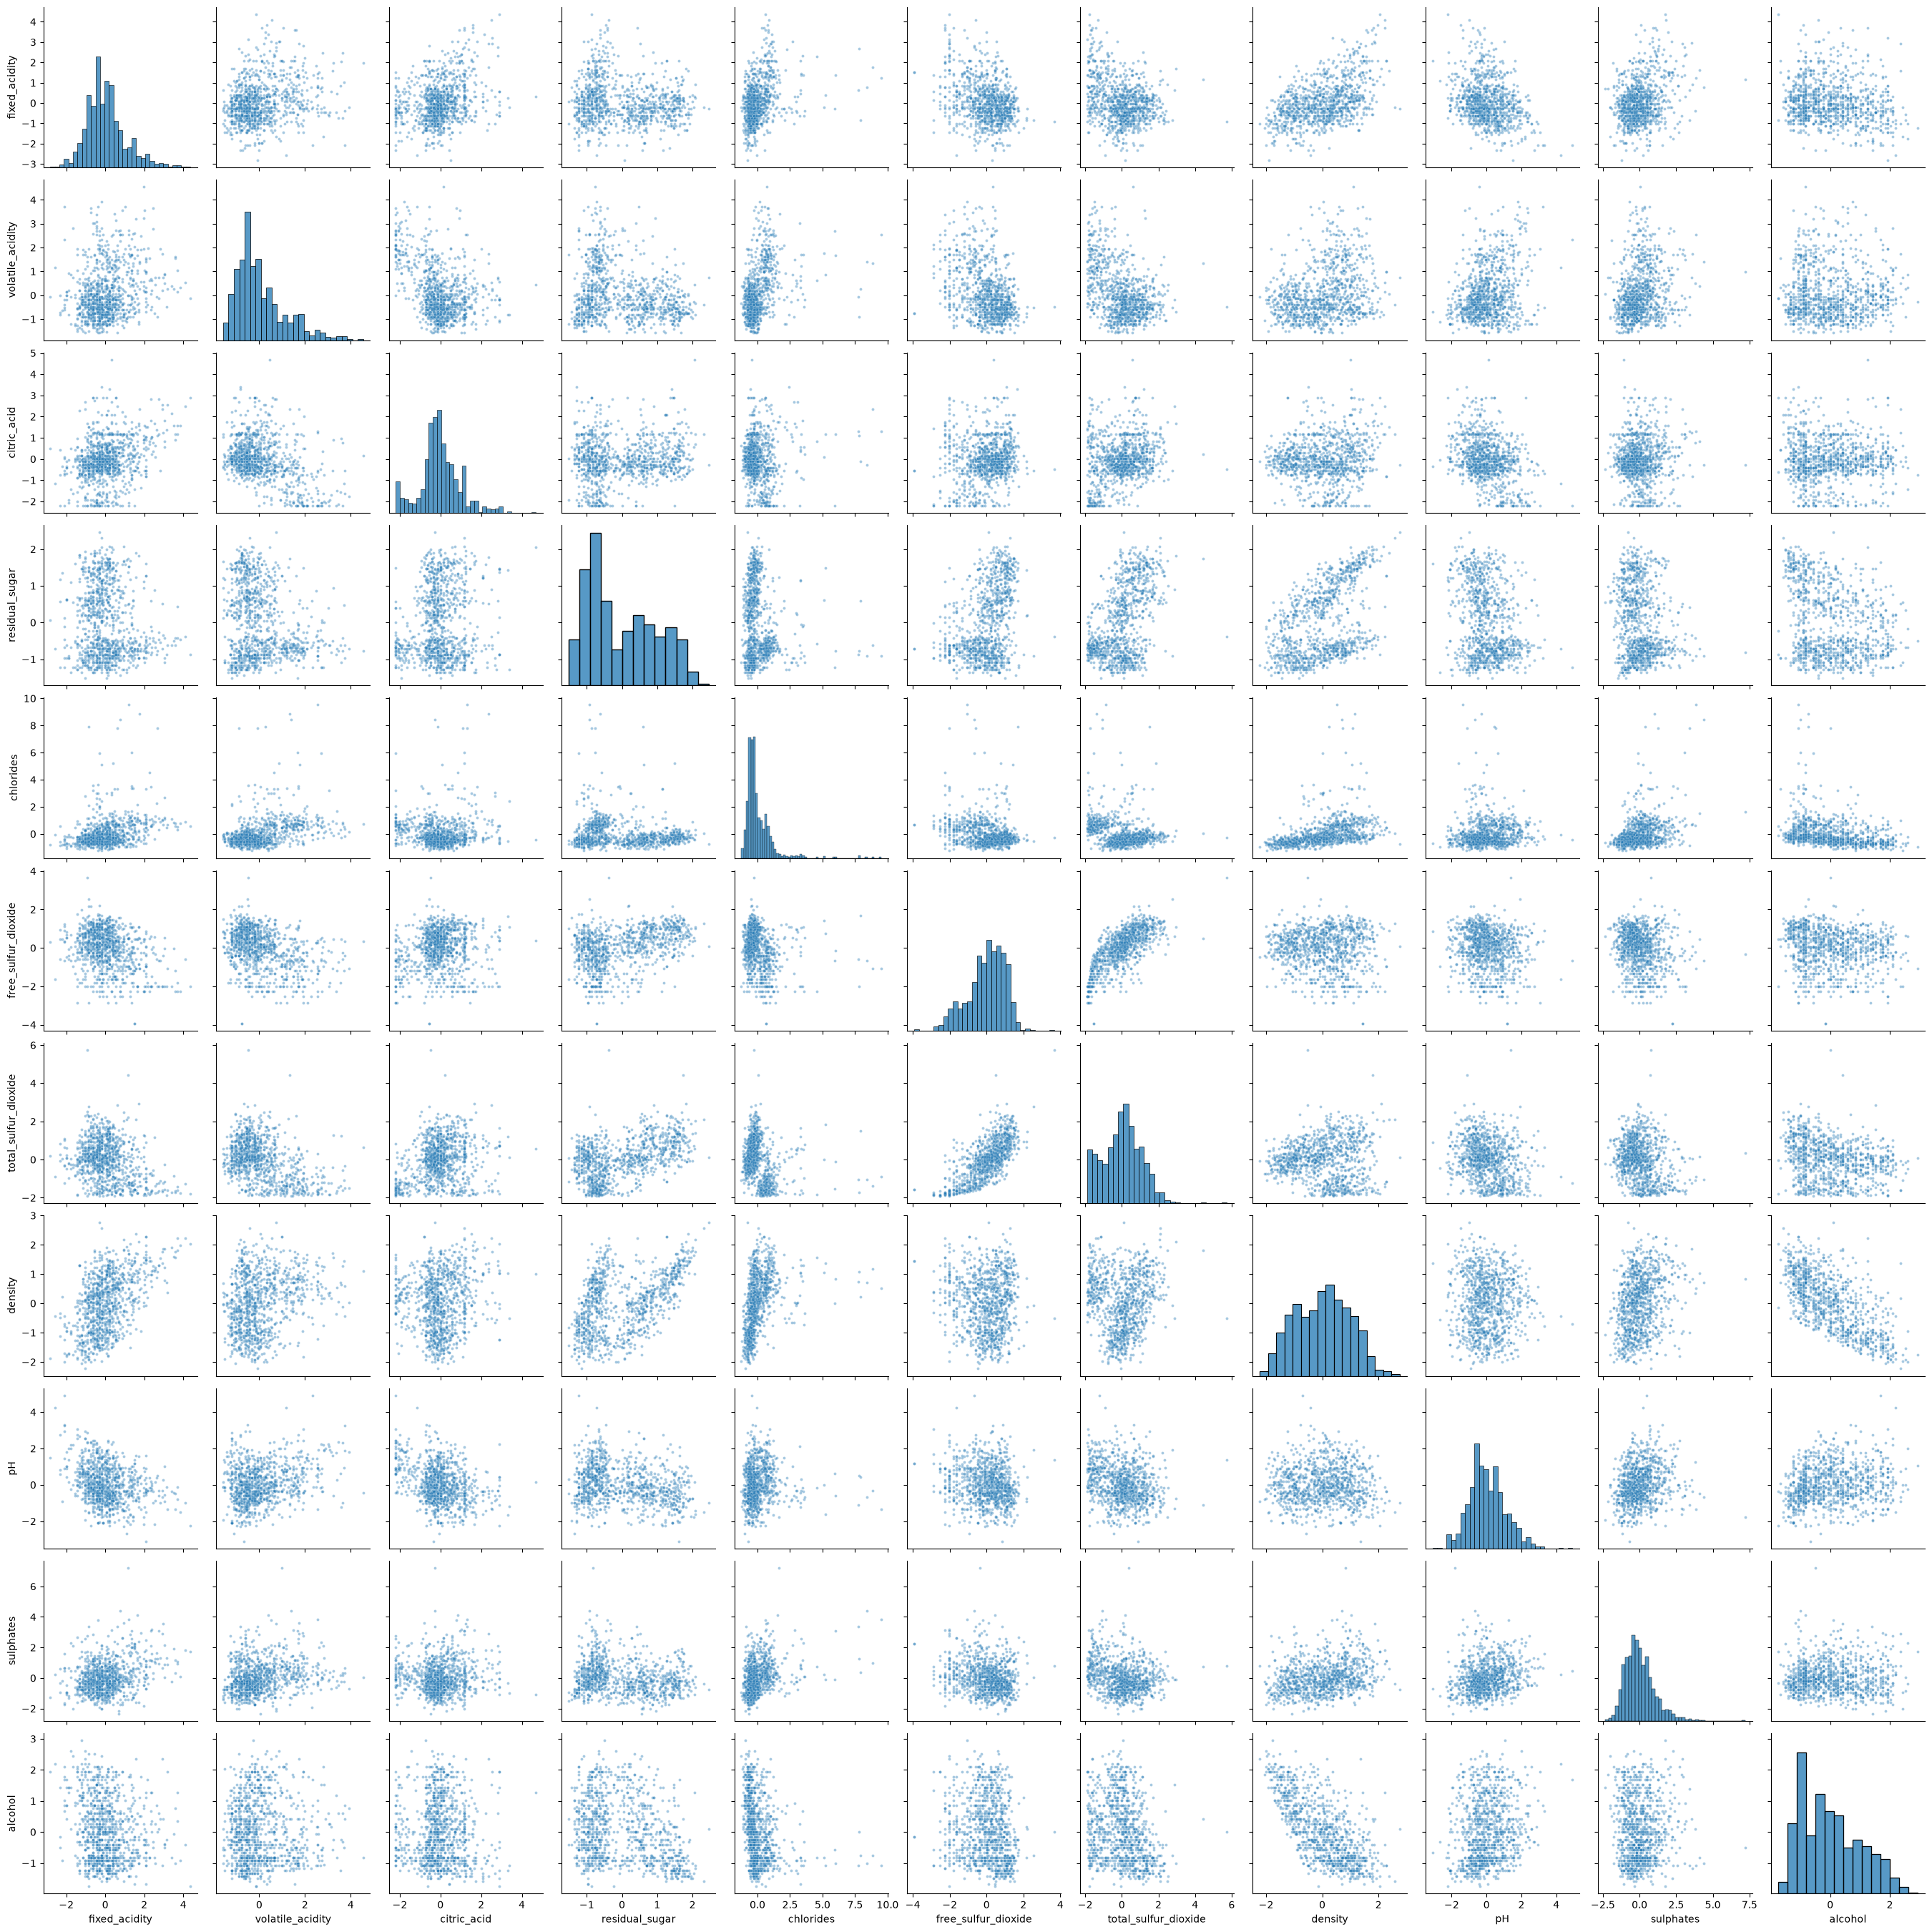

In [11]:
# Парные графики. Чтобы график строился быстро, берём случайные 1000 вин
sns.pairplot(data[float_columns].sample(1000, random_state=42),
             plot_kws={'s': 8, 'alpha': 0.4}, diag_kind='hist')
plt.show()

## Вопрос 3

* Постройте модель кластеризации методом K-средних с двумя кластерами.
* Проанализируйте кластеры по цвету вина.

> **Пояснение**
> - Создаём `KMeans(n_clusters=2)` и обучаем его **только на химических признаках** (цвет и качество не используем).
> - `fit_predict` возвращает номер кластера (0 или 1) для каждого вина. Сохраняем его в новый столбец `kmeans` — он понадобится в вопросе 6.
> - Чтобы понять, что нашёл алгоритм, строим таблицу `crosstab`: сколько красных и белых вин попало в каждый кластер. Если кластеры «чистые» (почти все вина кластера одного цвета), значит, по химии цвет различим легко.

In [12]:
# Обучаем K-средних с двумя кластерами на масштабированных признаках
km = KMeans(n_clusters=2, random_state=42, n_init=10)
data['kmeans'] = km.fit_predict(data[float_columns])

# Сколько вин в каждом кластере
data['kmeans'].value_counts()

kmeans
1    4834
0    1663
Name: count, dtype: int64

In [13]:
# Кластеры по цвету вина: строки — цвет, столбцы — номер кластера
pd.crosstab(data['color'], data['kmeans'])

kmeans,0,1
color,,
red,1576,23
white,87,4811


In [14]:
# То же в долях по цвету (какая часть вин каждого цвета попала в каждый кластер)
pd.crosstab(data['color'], data['kmeans'], normalize='index').round(3)

kmeans,0,1
color,,
red,0.986,0.014
white,0.018,0.982


## Вопрос 4

* Теперь постройте модели K-Means с количеством кластеров от 1 до 20.
* Для каждой модели запишите количество кластеров и значение инерции.
* Постройте график зависимости количества кластеров от инерции. Можно ли выделить какое-то идеальное количество кластеров?

> **Пояснение**
> - **Инерция** (`inertia_`) — сумма квадратов расстояний от каждого вина до центра его кластера. Чем она меньше, тем плотнее кластеры.
> - С ростом числа кластеров инерция всегда уменьшается (в пределе, когда кластеров столько же, сколько вин, она равна 0), поэтому просто «взять минимум» нельзя.
> - Используют **метод локтя**: на графике ищут место, где падение инерции резко замедляется (изгиб «локтя»). Дальше добавлять кластеры почти не имеет смысла.

In [15]:
inertia_list = []

for n in range(1, 21):
    km_n = KMeans(n_clusters=n, random_state=42, n_init=10)
    km_n.fit(data[float_columns])
    inertia_list.append({'n_clusters': n, 'inertia': km_n.inertia_})

inertia_df = pd.DataFrame(inertia_list).set_index('n_clusters')
inertia_df.round(1)

,inertia
n_clusters,
1,71467.0
2,55456.0
3,45199.9
4,40674.1
5,38203.5
6,36241.9
7,34307.7
8,33037.5
9,31976.4


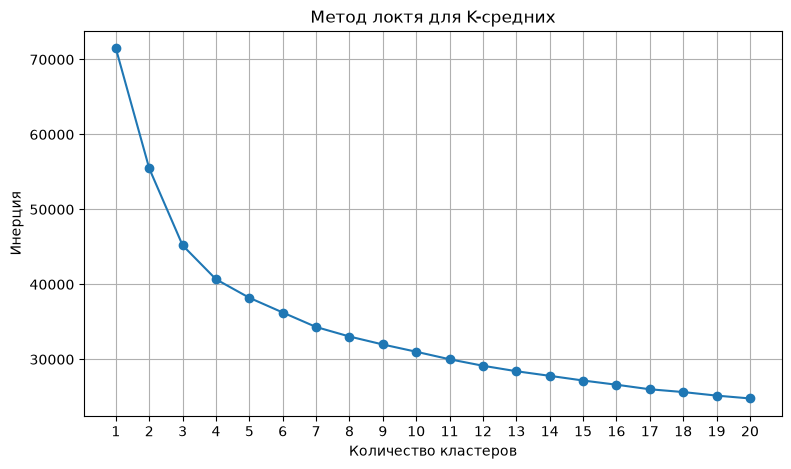

In [16]:
# График: инерция в зависимости от числа кластеров
ax = inertia_df.plot(marker='o', legend=False, figsize=(9, 5))
ax.set(xlabel='Количество кластеров', ylabel='Инерция',
       title='Метод локтя для K-средних')
ax.set_xticks(range(1, 21))
ax.grid()
plt.show()

## Вопрос 5

* Постройте модель агломеративного кластеризации с двумя кластерами.
* Сравните полученные результаты с результатами, полученными с помощью алгоритма K-средних, с точки зрения цвета вина.
* Визуализируйте дендрограмму, построенную с помощью агломеративного кластеризации. *Подсказка:* В SciPy есть модуль [`cluster.hierarchy`](https://docs.scipy.org/doc/scipy/reference/cluster.hierarchy.html#module-scipy.cluster.hierarchy), содержащий функции `linkage` и `dendrogram`, необходимые для построения карты связей и отображения полученной дендрограммы.

> **Пояснение**
> - `AgglomerativeClustering(n_clusters=2, linkage='ward')` сначала считает каждое вино отдельным кластером и постепенно склеивает ближайшие, пока не останется 2 кластера. Метод `ward` склеивает так, чтобы разброс внутри кластеров рос минимально.
> - Результат сохраняем в столбец `agglom` (понадобится в вопросе 6) и сравниваем с цветом, как и для K-средних.
> - **Дендрограмма** — «дерево склеиваний». По вертикали — расстояние, на котором объединялись кластеры; чем выше соединение, тем более непохожие группы склеены. Резкий скачок вверх на дереве подсказывает естественное число кластеров. Вин у нас несколько тысяч, поэтому показываем только последние 30 объединений (`truncate_mode='lastp'`), иначе дерево нечитаемо.

In [17]:
# Агломеративная кластеризация на двух кластерах
ag = AgglomerativeClustering(n_clusters=2, linkage='ward')
data['agglom'] = ag.fit_predict(data[float_columns])

# Кластеры по цвету вина
pd.crosstab(data['color'], data['agglom'])

agglom,0,1
color,,
red,31,1568
white,4755,143


In [18]:
# Сравнение двух методов: как совпали их кластеры между собой
pd.crosstab(data['kmeans'], data['agglom'], rownames=['kmeans'], colnames=['agglom'])

agglom,0,1
kmeans,,
0,51,1612
1,4735,99


Обратите внимание, что распределение по кластерам является произвольным: номера основных кластеров для красного и белого цветов могут не совпадать с приведёнными ниже, а также могут различаться при использовании метода K-средних и агломеративного кластерирования.

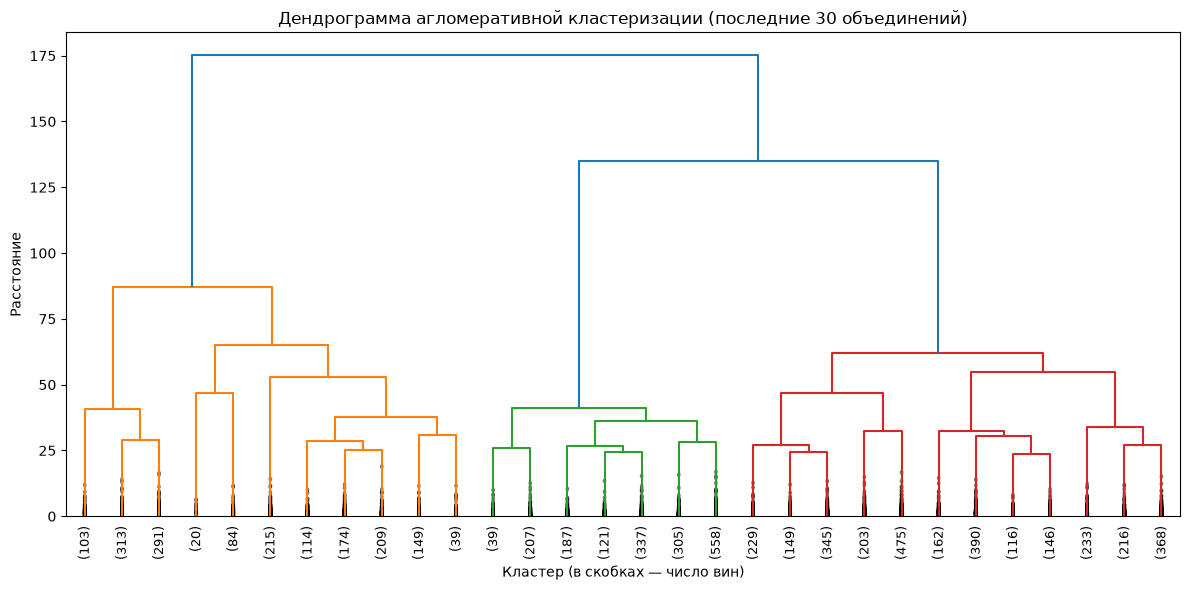

In [19]:
# Матрица связей (linkage) и дендрограмма
Z = linkage(data[float_columns], method='ward')

fig, ax = plt.subplots(figsize=(12, 6))
dendrogram(Z, truncate_mode='lastp', p=30, leaf_rotation=90, leaf_font_size=9,
           show_contracted=True, ax=ax)
ax.set(title='Дендрограмма агломеративной кластеризации (последние 30 объединений)',
       xlabel='Кластер (в скобках — число вин)', ylabel='Расстояние')
plt.tight_layout()
plt.show()

## Вопрос 6

В этом вопросе мы рассмотрим кластеризацию как один из способов инженерии признаков.

* Создайте **бинарную** целевую переменную `y`, указывающую, превышает ли показатель качества значение 7 или нет.
* Создайте переменную `X_with_kmeans` на основе набора данных `data`, удалив из него столбцы «quality», «color» и «agglom». Создайте из него `X_without_kmeans`, удалив столбец «kmeans».
* Для обоих наборов данных с помощью `StratifiedShuffleSplit` с 10 разбиениями обучите 10 классификаторов Random Forest и вычислите среднее значение показателей ROC-AUC.
* Сравните средние значения показателей ROC-AUC для моделей, использующих кластеры k-средних в качестве признака, и для модели, которая их не использует.

> **Пояснение**
> - Идея: **номер кластера можно использовать как новый признак**. Вдруг он содержит полезную информацию, которой нет в отдельных столбцах?
> - `y` — бинарная цель: `1` — вино с качеством выше 7 (редкое «отличное» вино), `0` — остальные.
> - Строим два набора признаков: с колонкой `kmeans` и без неё. Для каждого 10 раз случайно делим данные на обучение и тест (`StratifiedShuffleSplit` сохраняет долю редкого класса), обучаем Random Forest и считаем **ROC-AUC** (насколько хорошо модель отделяет хорошие вина от остальных; 0,5 — случайное угадывание, 1 — идеал).
> - В конце сравниваем средний ROC-AUC двух вариантов.

In [20]:
# Бинарная цель: качество выше 7
y = (data['quality'] > 7).astype(int)
print('Доля вин с качеством выше 7:', round(y.mean(), 4))

# Наборы признаков с кластерами K-средних и без них
X_with_kmeans = data.drop(['quality', 'color', 'agglom'], axis=1)
X_without_kmeans = X_with_kmeans.drop('kmeans', axis=1)

print(X_with_kmeans.shape, X_without_kmeans.shape)

Доля вин с качеством выше 7: 0.0305
(6497, 12) (6497, 11)


In [21]:
# Функция: 10 раз делим данные, обучаем Random Forest и возвращаем список ROC-AUC
def get_rf_auc(X, y):
    splitter = StratifiedShuffleSplit(n_splits=10, test_size=0.3, random_state=42)
    auc_list = []

    for train_idx, test_idx in splitter.split(X, y):
        X_tr, X_te = X.iloc[train_idx], X.iloc[test_idx]
        y_tr, y_te = y.iloc[train_idx], y.iloc[test_idx]

        rf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
        rf.fit(X_tr, y_tr)

        # ROC-AUC считается по вероятности класса 1
        auc_list.append(roc_auc_score(y_te, rf.predict_proba(X_te)[:, 1]))

    return auc_list

auc_with = get_rf_auc(X_with_kmeans, y)
auc_without = get_rf_auc(X_without_kmeans, y)

# Сравнение средних ROC-AUC
pd.DataFrame({'Средний ROC-AUC': [np.mean(auc_with), np.mean(auc_without)],
              'Разброс (std)': [np.std(auc_with), np.std(auc_without)]},
             index=['С кластерами k-средних', 'Без кластеров k-средних']).round(4)

,Средний ROC-AUC,Разброс (std)
С кластерами k-средних,0.8764,0.0270
Без кластеров k-средних,0.8789,0.0278


Давайте теперь выясним, влияет ли количество кластеров на это улучшение.

* Создайте базовый обучающий набор из `data`, ограничив его столбцами с числами с плавающей запятой.
* Для $n = 1, \ldots, 20$ выполните обучение алгоритма k-средних с $n$ кластерами. Примените к данным кодирование «one-hot» и добавьте их в **базовый** обучающий набор. Не добавляйте их к результатам предыдущей итерации.
* Обучите 10 моделей **логистической регрессии** и вычислите среднее значение показателя ROC-AUC.
* Постройте график средних значений показателя ROC-AUC.

> **Пояснение**
> - **One-hot кодирование** превращает номер кластера в набор столбцов из 0 и 1: например, кластер 2 из 3 становится `[0, 1, 0]`. Для линейной модели (логистической регрессии) это правильный способ подать категорию — иначе она решит, что кластер 2 «в два раза больше» кластера 1.
> - В цикле для каждого `n` от 1 до 20 берём **чистый базовый набор** (только float-признаки), добавляем к нему one-hot столбцы кластеров *именно этой* итерации (результаты прошлых итераций не накапливаем).
> - Для каждого `n` обучаем 10 логистических регрессий на разных разбиениях и берём средний ROC-AUC. График покажет, помогает ли увеличение числа кластеров.

In [22]:
# Базовый набор: только непрерывные (float) признаки
X_base = data[float_columns]

mean_auc_list = []

for n in range(1, 21):
    # Кластеризуем и кодируем номера кластеров в one-hot столбцы
    labels = KMeans(n_clusters=n, random_state=42, n_init=10).fit_predict(X_base)
    onehot = pd.get_dummies(labels, prefix='cluster').astype(float)
    onehot.index = X_base.index

    # Каждый раз добавляем к БАЗОВОМУ набору (а не к набору предыдущей итерации)
    X_n = pd.concat([X_base, onehot], axis=1)

    # 10 разбиений, логистическая регрессия, ROC-AUC
    splitter = StratifiedShuffleSplit(n_splits=10, test_size=0.3, random_state=42)
    auc_list = []
    for train_idx, test_idx in splitter.split(X_n, y):
        lr = LogisticRegression(max_iter=1000)
        lr.fit(X_n.iloc[train_idx], y.iloc[train_idx])
        auc_list.append(roc_auc_score(y.iloc[test_idx], lr.predict_proba(X_n.iloc[test_idx])[:, 1]))

    mean_auc_list.append({'n_clusters': n, 'mean_auc': np.mean(auc_list)})

auc_by_n = pd.DataFrame(mean_auc_list).set_index('n_clusters')
auc_by_n.round(4)

,mean_auc
n_clusters,
1,0.7918
2,0.7914
3,0.7897
4,0.7891
5,0.7919
6,0.7913
7,0.7925
8,0.7971
9,0.7923


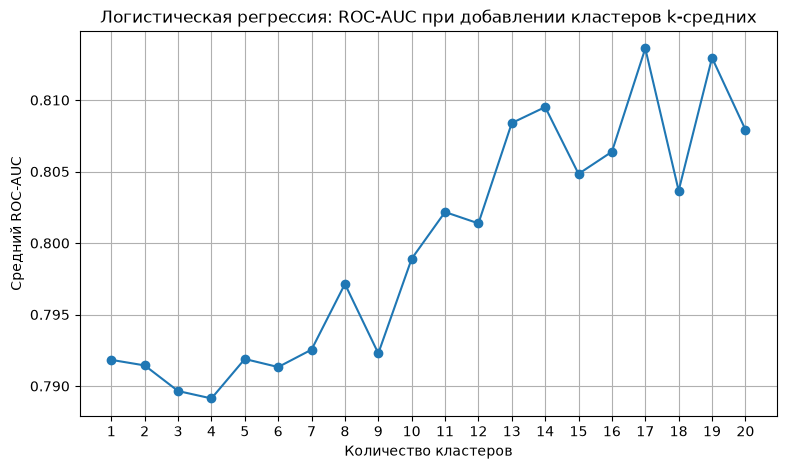

In [23]:
# График: средний ROC-AUC в зависимости от числа кластеров
ax = auc_by_n.plot(marker='o', legend=False, figsize=(9, 5))
ax.set(xlabel='Количество кластеров', ylabel='Средний ROC-AUC',
       title='Логистическая регрессия: ROC-AUC при добавлении кластеров k-средних')
ax.set_xticks(range(1, 21))
ax.grid()
plt.show()